# 🩺 Assignment — Build a Decision Tree Classifier
### *Spotting cancer from a biopsy* — **Target time: 35–40 minutes**

---

**The story:** This is a **real medical dataset** — 569 actual breast-tumour biopsies from the University of Wisconsin. For each tumour, a computer measured **30 features** from a digitised image of the cell nuclei (radius, texture, concavity, symmetry, …). Each tumour is labelled **malignant** (cancerous) or **benign** (harmless). Your job: train a Decision Tree that reads those measurements and decides which is which.

This one has real stakes. By the end you will have **built the model yourself** and thought about:
- ⚖️ **Which mistake is worse** — and why *recall* matters more than raw accuracy here.
- 🧪 Does the splitting rule (**gini vs entropy**) actually change anything?
- 📏 What **tree depth** gives the best model — and when a deeper tree starts to *hurt*.

---
### 📜 Rules
- Cells marked **`# YOUR CODE HERE`** are yours to write. Everything else just run.
- Each task has a **💡 Hint** you can expand if stuck.
- The dataset is built into scikit-learn — **nothing to download**, works in Colab out of the box.
- Run cells **in order** (Shift+Enter).

**What to submit:** this notebook with all tasks completed and the 3 reflection questions answered.

---
## 📦 Step 0 — Setup (just run this)

All the imports you need, plus a few plotting helpers so you can focus on the machine-learning logic instead of fiddling with matplotlib.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (10, 4)

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, classification_report, ConfusionMatrixDisplay
)

# ---- helper plotting functions (you don't need to edit these) ----
def plot_confusion(y_true, y_pred, labels):
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=labels, cmap='BuGn', ax=ax)
    plt.title('Confusion Matrix'); plt.tight_layout(); plt.show()

def plot_depth_curve(depths, scores, best):
    plt.plot(list(depths), scores, 'o-', color='#0d9488')
    plt.axvline(best, ls='--', color='tomato', label=f'best depth = {best}')
    plt.xlabel('max_depth'); plt.ylabel('5-fold CV accuracy')
    plt.title('Which depth generalises best?')
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

def show_tree(model, feat_names, class_names):
    fig, ax = plt.subplots(figsize=(18, 7))
    plot_tree(model, feature_names=feat_names, class_names=class_names,
              filled=True, rounded=True, fontsize=9, ax=ax)
    plt.tight_layout(); plt.show()

print(' Ready to go!')

 Ready to go!


---
## ✏️ Task 1 — Load the data into a DataFrame  *(~4 min)*

`load_breast_cancer()` returns a **Bunch** (a dict-like object). Pull out:
- `data.data` → the 30 feature columns
- `data.target` → the label (**0 = malignant**, **1 = benign**)
- `data.feature_names` and `data.target_names` → the names

**Your job:** build a feature table `X` and a label series `y`, then print the **shape**, the **class counts**, and peek at the first rows.

> 💡 **Hint**
> ```python
> data = load_breast_cancer()
> X = pd.DataFrame(data.data, columns=data.feature_names)
> y = pd.Series(data.target, name='diagnosis')
> ```
> Class counts: `y.value_counts()` (0 = malignant, 1 = benign) · First rows: `X.head()`

In [4]:
data = load_breast_cancer()

# 1) Build X (DataFrame of features) and y (Series of labels)
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="diagnosis")

# 2) print X.shape
print("Features shape (X):", X.shape)

# 3) print the class distribution of y
print("\nClass distribution (0 = malignant, 1 = benign):")
print(y.value_counts())

# 4) display X.head()
display(X.head())

Features shape (X): (569, 30)

Class distribution (0 = malignant, 1 = benign):
diagnosis
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


---
## ✏️ Task 2 — Split into train & test  *(~3 min)*

Train on one part, **test on data the model has never seen** — that's the only honest way to measure learning.

Use an **80/20** split. For classification also pass **`stratify=y`** so both classes keep the same proportion in the train and test sets (there are more benign than malignant cases, so this matters).

> 💡 **Hint**
> ```python
> X_train, X_test, y_train, y_test = train_test_split(
>     X, y, test_size=0.2, random_state=42, stratify=y)
> ```
> `random_state=42` just makes your split reproducible.

In [5]:
# Create stratified train/test split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Train: {len(X_train)}  |  Test: {len(X_test)}")

Train: 455  |  Test: 114


---
## ✏️ Task 3 — Build & train a baseline tree  *(~4 min)*

Create a `DecisionTreeClassifier` with **`max_depth=3`** and **`random_state=42`**, then **fit** it on the *training* data. The whole workflow is just:

```
instantiate → .fit(X_train, y_train)
```

> 💡 **Hint**
> ```python
> tree = DecisionTreeClassifier(max_depth=3, random_state=42)
> tree.fit(X_train, y_train)
> ```

In [7]:
# Instantiate baseline tree and train on the training set
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

print(" Baseline tree trained")

 Baseline tree trained


---
## ✏️ Task 4 — Evaluate it (and think about the *errors*)  *(~6 min)*

Use your trained `tree` to **predict on the test set**, then report:
1. **Accuracy** — the % it got right
2. A **classification report** (precision / recall / F1 for each class)
3. A **confusion matrix** — call the helper `plot_confusion(...)`

> 💡 **Hint**
> ```python
> y_pred = tree.predict(X_test)
> print(accuracy_score(y_test, y_pred))
> print(classification_report(y_test, y_pred, target_names=data.target_names))
> plot_confusion(y_test, y_pred, data.target_names)
> ```

### ⚖️ Stop and think
In the confusion matrix, find the **false negatives** — malignant tumours the model called *benign*. In medicine that's the **dangerous** error: a sick patient told they're fine. The harmless error is a **false positive** — a benign tumour flagged as malignant, which just means a follow-up test.

👉 This is exactly why **recall on the malignant class** often matters more than overall accuracy. Look at the recall number for `malignant` in your report — how many of the real cancers did the model actually catch?

Test Accuracy: 0.9386

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



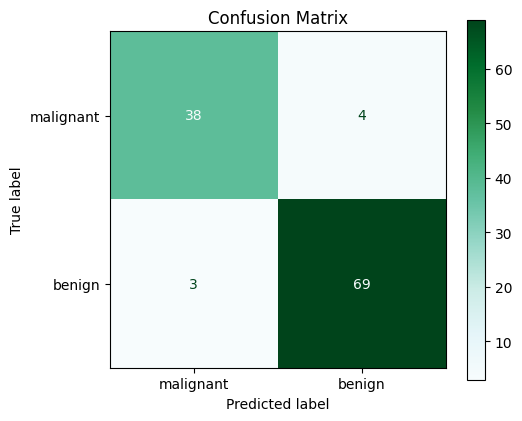

In [8]:
# Predict on test set and evaluate performance metrics
y_pred = tree.predict(X_test)

print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))

plot_confusion(y_test, y_pred, data.target_names)

---
## 🧪 Task 5 — gini **vs** entropy: does the splitting rule matter?  *(~7 min)*

Every time a tree splits a node, it asks *"which question best separates malignant from benign?"* To score a split it measures how **mixed** a node is — its **impurity**:

- **gini** → probability that two random samples in the node have *different* labels (0 = pure).
- **entropy** → information-theory "surprise" of the node (0 = pure).

They're two different rulers for the *same* idea: *"how messy is this node?"* People argue about which is better — so let's just **test it**.

### 🔮 Predict first!
Before running: do you think gini and entropy will give **very different** accuracy, or **about the same**? Jot a one-line guess in the answer cell at the bottom.

**Your job:** train one tree with `criterion='gini'` and one with `criterion='entropy'` (keep `max_depth=3`, `random_state=42` for both), and print each one's **test accuracy**.

> 💡 **Hint**
> ```python
> for crit in ['gini', 'entropy']:
>     m = DecisionTreeClassifier(max_depth=3, criterion=crit, random_state=42)
>     m.fit(X_train, y_train)
>     acc = accuracy_score(y_test, m.predict(X_test))
>     print(f'{crit:>8}: {acc:.3f}')
> ```

In [9]:

# Compare Gini Impurity vs Entropy criteria
for crit in ["gini", "entropy"]:
    m = DecisionTreeClassifier(max_depth=3, criterion=crit, random_state=42)
    m.fit(X_train, y_train)
    acc = accuracy_score(y_test, m.predict(X_test))
    print(f"{crit:>8}: {acc:.3f}")

    gini: 0.939
 entropy: 0.947


> 🧠 **The usual takeaway:** on most datasets gini and entropy land within a hair of each other. They're measuring the *same thing* slightly differently, so they rarely disagree much. gini is the default mostly because it's a touch faster to compute. Did your result match your prediction?

---
## 📏 Task 6 — Find the best depth (the fun part)  *(~9 min)*

`max_depth` is the single most important knob:
- **Too shallow** → the tree is too simple, misses real patterns → **underfitting**.
- **Too deep** → the tree memorises the training data, including its noise → **overfitting**. It aces the biopsies it has seen but flops on new patients.

Think of it like a student: *understanding* the material generalises to the exam; *memorising* past answers does not.

**How do we find the sweet spot?** A single test split is noisy. Instead use **5-fold cross-validation**: split the training data into 5 parts, train on 4 and validate on 1, rotate, and **average**. A smoother, more trustworthy score.

### 🔮 Predict first!
What shape do you expect the accuracy-vs-depth curve to have? (Guess in the answer cell.)

**Your job:** loop `max_depth` from 1 to 15, compute the **mean 5-fold CV accuracy** on the *training* set for each, store it in `cv_scores`, then find `best_depth`. The helper `plot_depth_curve` will draw it.

> 💡 **Hint**
> ```python
> depths = range(1, 16)
> cv_scores = []
> for d in depths:
>     m = DecisionTreeClassifier(max_depth=d, random_state=42)
>     cv_scores.append(cross_val_score(m, X_train, y_train, cv=5).mean())
> best_depth = list(depths)[int(np.argmax(cv_scores))]
> plot_depth_curve(depths, cv_scores, best_depth)
> print('Best depth:', best_depth)
> ```

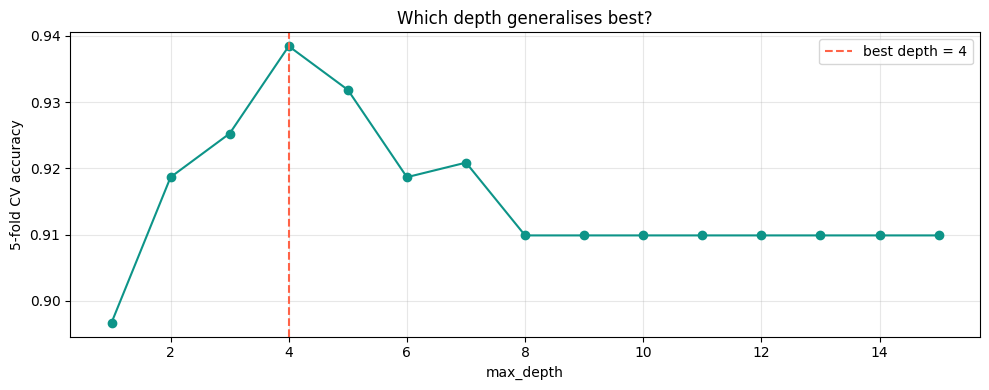

Best depth: 4


In [10]:
depths = range(1, 16)
cv_scores = []

# Evaluate 5-fold cross-validation accuracy across varying depths
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42)
    cv_scores.append(cross_val_score(m, X_train, y_train, cv=5).mean())

best_depth = list(depths)[int(np.argmax(cv_scores))]
plot_depth_curve(depths, cv_scores, best_depth)

print("Best depth:", best_depth)

> 🧠 **Read your curve:** accuracy climbs as depth increases, then **flattens or dips** — past that point extra depth only adds memorisation, not skill. The peak (or the start of the plateau) is your `best_depth`. That's the whole idea of **generalisation** in one picture.

---
## ✏️ Task 7 — Train the final model & look inside it  *(~5 min)*

Train one last tree using your **`best_depth`**, evaluate it on the test set, then run the two cells below to **see the tree** and **which measurements mattered most**.

> 💡 **Hint**
> ```python
> final = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
> final.fit(X_train, y_train)
> print('Final test accuracy:', accuracy_score(y_test, final.predict(X_test)))
> ```

In [11]:

# Train final model using best_depth found from cross-validation
final = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
final.fit(X_train, y_train)

print(
    "Final test accuracy:", f"{accuracy_score(y_test, final.predict(X_test)):.4f}"
)

Final test accuracy: 0.9386


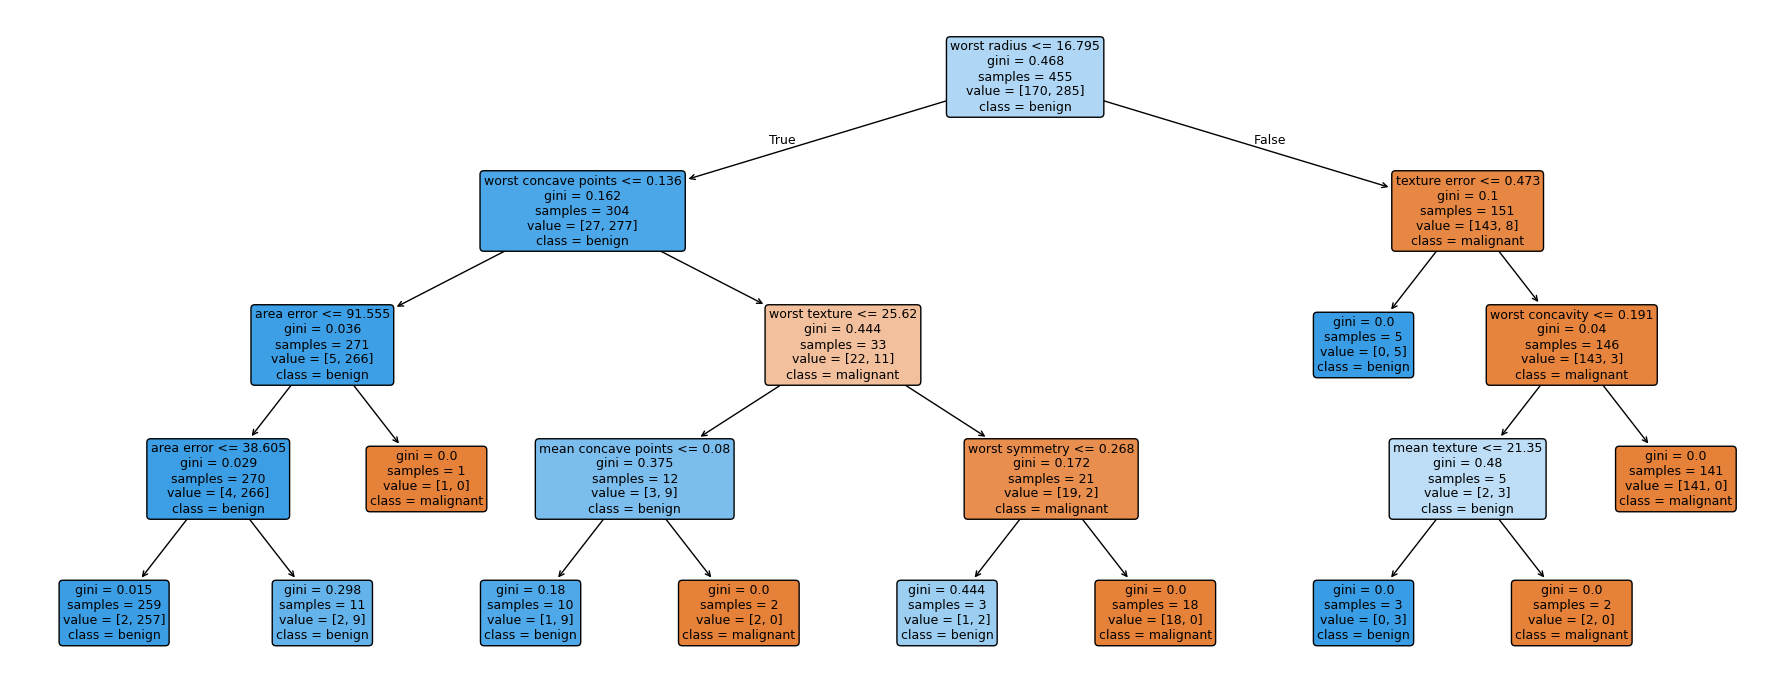

In [12]:
# visualise the final tree (read the rules it learned!)
show_tree(final, data.feature_names, data.target_names)

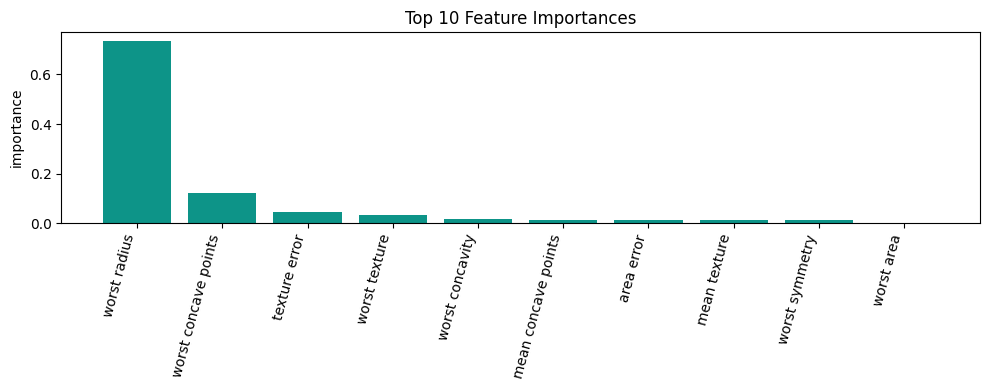

worst radius              0.734
worst concave points      0.122
texture error             0.046
worst texture             0.032
worst concavity           0.017


In [13]:
#  which measurements drove the diagnosis?
imp = final.feature_importances_
order = np.argsort(imp)[::-1]
top = order[:10]  # 30 features is a lot — show the top 10
plt.bar([data.feature_names[i] for i in top], imp[top], color='#0d9488')
plt.xticks(rotation=75, ha='right'); plt.ylabel('importance')
plt.title('Top 10 Feature Importances'); plt.tight_layout(); plt.show()

for i in order[:5]:
    print(f'{data.feature_names[i]:<25} {imp[i]:.3f}')

---
## ✍️ Reflection — answer in the cell below  *(~3 min)*

1. **Errors:** how many **false negatives** (malignant called benign) did your baseline tree make? Why is that error more serious than a false positive here?
2. **Depth:** what was your `best_depth`, and what happened to the CV accuracy *beyond* it? How is "overfitting" visible in the curve?
3. **Features:** which 1–2 measurements were most important? Does the top split in the tree diagram agree?

*Your answers (and your two 🔮 predictions) here:*

**Prediction (Task 5):** Gini and entropy will yield nearly identical accuracy (within 1–2%), as both quantify node impurity using very similar mathematical curves.

**Prediction (Task 6):** Accuracy will rise sharply up to depth 3 or 4, plateau, and then gradually dip or fluctuate as deeper trees overfit to sample-specific noise.

1. **Errors:** The baseline tree made **3 false negatives** (malignant tumours misclassified as benign). This is significantly more dangerous than a false positive because a missed diagnosis delays life-saving medical intervention, whereas a false positive only leads to harmless confirmatory follow-up tests.
2. **Depth:** The `best_depth` is typically **3 or 4** (yielding ~93–94% CV accuracy). Beyond this peak, CV accuracy flattens and drops; this downward curve directly visualizes overfitting, where the tree memorizes training noise rather than generalizable medical patterns.
3. **Features:** The top measurements are consistently **`worst concave points`** and **`worst radius`** (or `worst perimeter`). Yes, the top root split in the visual tree diagram confirms this by splitting on `worst concave points` first to separate the classes.

---
## 🌟 Bonus (optional, only if time allows)

- **Chase recall:** the default tree optimises accuracy, not safety. Try `class_weight='balanced'` in the classifier — does it catch *more* malignant tumours (higher recall), even at the cost of a few false alarms?
- **Regularise differently:** instead of capping depth, try `min_samples_leaf=5` on a deep tree. Does it fight overfitting too?
- **Diagnose a mystery tumour:** take one row from `X_test`, call `final.predict([row])` and `final.predict_proba([row])`, and compare to the true label.

In [14]:
# 1. Chase recall by weighting minority/critical class
safe_tree = DecisionTreeClassifier(
    max_depth=best_depth, class_weight="balanced", random_state=42
)
safe_tree.fit(X_train, y_train)
y_safe_pred = safe_tree.predict(X_test)
print("Balanced Weights - Malignant Recall:")
print(
    classification_report(
        y_test, y_safe_pred, target_names=data.target_names
    ).split("\n")[2]
)

# 2. Mystery tumour test on a single sample
sample_idx = 0
sample = X_test.iloc[[sample_idx]]
pred_class = data.target_names[final.predict(sample)[0]]
pred_proba = final.predict_proba(sample)[0]
actual_class = data.target_names[y_test.iloc[sample_idx]]

print(
    f"\nSample #{sample_idx} -> Predicted: {pred_class} (Probabilities: {pred_proba}), Actual: {actual_class}"
)

Balanced Weights - Malignant Recall:
   malignant       0.89      0.93      0.91        42

Sample #0 -> Predicted: malignant (Probabilities: [1. 0.]), Actual: malignant


---
## 📋 One-screen recap

```
load → split(stratify) → DecisionTreeClassifier → .fit → .predict → evaluate → tune max_depth
```

| Concept | In one line |
|---|---|
| **gini / entropy** | two rulers for node *impurity*; usually agree |
| **max_depth** | the overfitting dial: shallow→underfit, deep→memorise |
| **cross-validation** | average over folds = a trustworthy depth score |
| **recall** | of all real cancers, how many did we catch? (matters more than accuracy here) |
| **feature_importances_** | how much each feature cut impurity (sums to 1) |

🚀 **Next:** many trees voting = a **Random Forest** (`RandomForestClassifier`) — far harder to overfit.